# 07 — Enough snow on the pistes? Season length, continuity, and what can be made

**Almaty SuperSki terrain analytics — an independent open-data case study**
Dias Irishev · Geo & Weather Data Scientist, Almaty

Notebooks 02 and 06 answer *where* snow is and *how often* a pixel looked like
snow. Useful, and not the operator's question. The operator asks whether the
ground that will carry pistes holds snow **long enough**, **without breaking**,
and where it does not, whether the weather allows the missing snow to be
**made**.

A frequency map cannot answer any of the three. "Snow on 95 % of usable dates"
is consistent with a season that starts in mid-December, and with a cover that
melts and refreezes every other week. So this notebook measures three different
things:

1. **The observed season** — the interval between the first and the last snow
   detection of a season, per pixel, with the gaps in the record carried as
   brackets and censoring reported rather than averaged in.
2. **Continuity** — snow-free looks *inside* that interval, and the honest
   limit on what 15–25 looks a season can see.
3. **The snowmaking window** — hours below three published wet-bulb thresholds,
   from hourly reanalysis, with the elevation correction swept across ±2 °C
   because it is the largest assumption here.

Everything is computed by `src/snow_sufficiency.py` and run end to end by
`src/pipeline_snow_sufficiency.py`. This notebook calls that module rather than
reimplementing it, so the tables, the figure, `METHODS.md` §22 and this page
cannot drift apart.

> **Nothing here is a forecast, a snow depth or a snowmaking budget.** Four
> seasons is not a climatology, no probability is attached to anything, and
> water supply, pumping capacity and gun type are not published for this
> project. The boundary is hand-drawn and not official.

In [1]:
import os

os.environ["KZ_AREA"] = "superski"        # must be set before importing config

import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))

import operating_area as OA
import pipeline_snow_sufficiency as PS
import snow_sufficiency as SS
import weather
from config import (LAPSE_RATE_C_PER_KM, LAPSE_SENSITIVITY_C, MIN_VALID_OBS,
                    OUT_PNG, OUT_TAB, RAIN_ON_SNOW_MM, S2_RES_M, SEASONS,
                    SNOWMAKING_WETBULB_C, SUFFICIENCY_BAND_M)
from grids import DEM_GRID as G
from grids import make_grid
from pipeline_snow import historical_days, load_days
from ski_terrain import GREEN_BLUE_MAX_DEG
from snow import season_span, snow_frequency

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

poly, props = OA.load()
dem, slope = PS._terrain()
S2 = make_grid(S2_RES_M)
M20 = OA.mask(S2, poly)
DEM20, SLOPE20 = PS._lift_to_20m(dem, S2), PS._lift_to_20m(slope, S2)
PX_HA = S2.res ** 2 / 1e4

DAYS, _manifest, _failed = load_days(verbose=False)
HIST = historical_days(DAYS)

print(f"boundary    : {M20.sum() * PX_HA:,.0f} ha on the {S2.res:.0f} m snow grid")
print(f"seasons     : {', '.join(s.replace('_', '/') for s in SEASONS)}")
print(f"observations: {len(HIST)} usable dates inside them")
print(f"bands       : {SUFFICIENCY_BAND_M:.0f} m, gradient split at "
      f"{GREEN_BLUE_MAX_DEG:.2f} deg")
print(f"thresholds  : wet bulb {SNOWMAKING_WETBULB_C} C, "
      f"lapse {LAPSE_RATE_C_PER_KM} C/km swept {LAPSE_SENSITIVITY_C}")

boundary    : 1,776 ha on the 20 m snow grid
seasons     : 2022/23, 2023/24, 2024/25, 2025/26
observations: 111 usable dates inside them
bands       : 200 m, gradient split at 19.29 deg
thresholds  : wet bulb (-2.0, -4.0, -6.0) C, lapse 6.5 C/km swept (-2.0, -1.0, 0.0, 1.0, 2.0)


## 1. Where it is measured

Two readings of "piste ground", carried side by side rather than picking one.
**Gentle** (≤ 19.29°) is what beginner and intermediate runs need — the ground
notebook 06 counts as green/blue. **Skiable** (15–35°) is the project's
standard definition of ski terrain, which keeps this page comparable with
notebook 05's three-area work.

The two overlap between 15° and 19.29°, deliberately: they answer different
questions and neither is a subset worth hiding.

In [2]:
GROUNDS = SS.ground_masks(SLOPE20, M20)
BANDS = SS.band_edges(DEM20, M20)

rows = []
for name, m in GROUNDS.items():
    rows.append({"ground": name, "area_ha": round(m.sum() * PX_HA, 1),
                 "share_of_boundary": round(m.sum() / M20.sum(), 3),
                 "median_slope_deg": round(float(np.median(SLOPE20[m])), 1),
                 "elev_min_m": round(float(DEM20[m].min())),
                 "elev_max_m": round(float(DEM20[m].max()))})
rows.append({"ground": "everything inside the boundary",
             "area_ha": round(M20.sum() * PX_HA, 1), "share_of_boundary": 1.0,
             "median_slope_deg": round(float(np.median(SLOPE20[M20])), 1),
             "elev_min_m": round(float(DEM20[M20].min())),
             "elev_max_m": round(float(DEM20[M20].max()))})
print(pd.DataFrame(rows).to_string(index=False))
print(f"\n{len(BANDS)} bands: {BANDS[0][0]:.0f} to {BANDS[-1][1]:.0f} m")

                        ground  area_ha  share_of_boundary  median_slope_deg  elev_min_m  elev_max_m
           gentle (<=19.3 deg)    363.2              0.204              13.3        1775        3291
           skiable (15-35 deg)   1226.9              0.691              28.2        1778        3296
everything inside the boundary   1775.9              1.000              28.8        1775        3296

9 bands: 1600 to 3400 m


## 2. The observed season, and why it is a lower bound

`snow.season_span` walks one season's valid observations twice. The first pass
records the first and the last snow detection per pixel. The second finds the
last snow-free look *before* the first snow, the first snow-free look *after*
the last, and counts the snow-free looks *inside*.

What is reported is `last_snow_day − first_snow_day`: the interval the record
actually saw snow across. It is **not** an interpolated count of snow-covered
days. With a median of 15–25 usable looks a season, interpolation would invent
days nobody observed.

That makes every span a **lower bound**, and the two brackets say by how much.
Take the beginner band one season at a time:

In [3]:
SPANS = {s: season_span(HIST, s) for s in SEASONS}

gentle = [g for g in GROUNDS if g.startswith("gentle")][0]
skiable = [g for g in GROUNDS if g != gentle][0]
beginner = GROUNDS[gentle] & (DEM20 >= 1800) & (DEM20 < 2000)

rows = []
for s, sp in SPANS.items():
    est = beginner & sp["has_snow"] & np.isfinite(sp["span_days"])
    from snow import day_to_date
    rows.append({
        "season": s.replace("_", "/"),
        "first snow (median)": day_to_date(float(np.median(sp["first_snow_day"][est])), sp["origin"]),
        "last snow (median)": day_to_date(float(np.median(sp["last_snow_day"][est])), sp["origin"]),
        "observed span (d)": float(np.median(sp["span_days"][est])),
        "onset bracket (d)": SS._nanmed(sp["onset_bracket_days"][est]),
        "meltout bracket (d)": SS._nanmed(sp["meltout_bracket_days"][est]),
        "upper bound (d)": float(np.median(
            sp["span_days"][est] + np.nan_to_num(sp["onset_bracket_days"][est])
            + np.nan_to_num(sp["meltout_bracket_days"][est]))),
        "left censored": round(float(sp["left_censored"][est].mean()), 3),
        "right censored": round(float(sp["right_censored"][est].mean()), 3),
        "looks (median)": int(np.median(sp["n_valid"][est])),
    })
beg = pd.DataFrame(rows)
print(f"gentle ground, 1,800-2,000 m — {beginner.sum() * PX_HA:.1f} ha\n")
print(beg.to_string(index=False))

lo, hi = beg["observed span (d)"].min(), beg["upper bound (d)"].max()
print(f"\nshortest observed span      {beg['observed span (d)'].min():.0f} d "
      f"({beg.loc[beg['observed span (d)'].idxmin(), 'season']})")
print(f"longest observed span       {beg['observed span (d)'].max():.0f} d")
print(f"shortest season's ceiling   {beg['upper bound (d)'].min():.0f} d")
print(f"longest season's floor      {beg['observed span (d)'].max():.0f} d")
print(f"-> seasons separable?       "
      f"{beg['observed span (d)'].max() > beg['upper bound (d)'].min()}")
print(f"-> all that can be said     the season fell somewhere in {lo:.0f}-{hi:.0f} days")

gentle ground, 1,800-2,000 m — 35.5 ha

 season first snow (median) last snow (median)  observed span (d)  onset bracket (d)  meltout bracket (d)  upper bound (d)  left censored  right censored  looks (median)
2022/23          2022-11-13         2023-03-26              130.0               12.0                  5.0            145.0          0.025           0.022              20
2023/24          2023-11-11         2024-03-25              135.0                5.0                 27.0            167.0          0.134           0.117              16
2024/25          2024-11-10         2025-03-20              130.0               15.0                 10.0            144.0          0.778           0.013              15
2025/26          2025-12-27         2026-03-30               93.0               27.0                 15.0            135.0          0.153           0.006              19

shortest observed span      93 d (2025/26)
longest observed span       135 d
shortest season's ceiling   135 

The shortest season's ceiling lands **exactly** on the longest season's floor.
2025/26 was the shortest of the four — the direction is certain, because its
upper bound does not clear the others' lower bounds — and four seasons of
optical satellite cannot say by how much. That is the honest result, and it is
more useful than a single number: it says what a second sensor would buy.

**Censoring is reported, not averaged in.** Where no snow-free look exists
before the first snow detection, or after the last, the season runs past what
the record can see. Higher up, that is the normal case:

In [4]:
SEASON_DF = SS.season_table(HIST, DEM20, SLOPE20, M20, PX_HA)
SUMMARY = SS.season_summary(SEASON_DF)

cols = ["band_low_m", "band_high_m", "area_ha", "median_span_days",
        "span_envelope_low_days", "span_envelope_high_days",
        "left_censored_share", "right_censored_share",
        "seasons_resolved", "min_valid_obs"]
print(f"{gentle}\n")
print(SUMMARY[SUMMARY.ground == gentle][cols].to_string(index=False))

gentle (<=19.3 deg)

 band_low_m  band_high_m  area_ha  median_span_days  span_envelope_low_days  span_envelope_high_days  left_censored_share  right_censored_share  seasons_resolved  min_valid_obs
     1800.0       2000.0     35.5             130.0                    93.0                    167.0                0.272                 0.040             False             15
     2000.0       2200.0     91.9             146.0                   138.0                    172.0                0.593                 0.140             False             22
     2200.0       2400.0     60.2             158.5                   148.0                    177.0                0.780                 0.390              True             23
     2400.0       2600.0     34.7             173.5                   152.0                    178.0                0.845                 0.737              True             23
     2600.0       2800.0     24.3             174.5                   170.0                   

Read `seasons_resolved` only next to the censoring columns. Where an end is
censored the bracket is unknown and adds nothing, so the interval is
artificially tight and "resolved" means nothing. At and above 2,400 m roughly
three quarters to nine tenths of pixels are censored at both ends, and the
~171 days those bands report is simply the 1 November – 30 April observation
window.

The one band where the record genuinely sees snow arrive *and* leave is the
beginner band — which is also the band a December opening depends on.

## 3. Continuity, and what the record cannot see

`breaks` counts snow-free valid observations strictly inside the span;
`continuity` is snow looks over snow-plus-free looks inside it.

In [5]:
print(SUMMARY[["ground", "band_low_m", "median_breaks", "median_continuity",
               "min_valid_obs"]].to_string(index=False))

gaps = []
for s, sp in SPANS.items():
    dates = sorted(d["date"] for d in HIST
                   if SEASONS[s][0] <= d["date"] <= SEASONS[s][1])
    dd = pd.to_datetime(pd.Series(dates)).diff().dt.days.dropna()
    gaps.append({"season": s.replace("_", "/"), "dates": len(dates),
                 "median gap (d)": float(dd.median()),
                 "p90 gap (d)": float(dd.quantile(0.9)),
                 "longest gap (d)": float(dd.max())})
print("\ngaps between usable observations:")
print(pd.DataFrame(gaps).to_string(index=False))

             ground  band_low_m  median_breaks  median_continuity  min_valid_obs
gentle (<=19.3 deg)      1800.0            0.0              0.969             15
gentle (<=19.3 deg)      2000.0            0.5              0.966             22
gentle (<=19.3 deg)      2200.0            0.5              0.979             23
gentle (<=19.3 deg)      2400.0            0.0              1.000             23
gentle (<=19.3 deg)      2600.0            0.0              1.000             24
gentle (<=19.3 deg)      2800.0            0.0              1.000             25
gentle (<=19.3 deg)      3000.0            0.0              1.000             25
gentle (<=19.3 deg)      3200.0            0.5              0.982             25
skiable (15-35 deg)      1800.0            1.0              0.688             12
skiable (15-35 deg)      2000.0            1.0              0.866             15
skiable (15-35 deg)      2200.0            0.5              0.970             13
skiable (15-35 deg)      240

Median breaks: **0**, everywhere. The cover was never *seen* to break.

That is a weaker statement than it reads. The median gap between usable looks
is about a week and a half, and the longest gaps run to several weeks, so **no
thaw shorter than that is visible**. "Never seen to break" is not "never
broke", and section 7 measures, from an independent dataset, what the satellite
is too sparse to see.

## 4. The same elevation, two gradients

The site-wide result in notebook 06 is that the gentle ground is the *sunny*
ground: 168 h of December sun against 110 h for the boundary as a whole. Inside
a single low band that reverses, and the reversal is what decides where
snowmaking is actually needed.

In [6]:
ins_dec = np.load(PS.INTERIM / "insolation" / "2027_12.npz")["total"]
DEC20 = PS._lift_to_20m(ins_dec, S2)
r3 = snow_frequency([d for d in HIST if d["date"][5:7] == "03"])
F3, OK3 = r3["frequency"], r3["n_valid"] >= MIN_VALID_OBS

rows = []
for lo_m, hi_m in BANDS[:4]:
    for name, m in GROUNDS.items():
        sel = m & (DEM20 >= lo_m) & (DEM20 < hi_m)
        if sel.sum() * PX_HA < 4:
            continue
        ok = sel & OK3
        rows.append({
            "band": f"{lo_m:.0f}-{hi_m:.0f}", "ground": name,
            "area_ha": round(sel.sum() * PX_HA, 1),
            "median_slope_deg": round(float(np.median(SLOPE20[sel])), 1),
            "dec_insolation_kwh": round(float(np.median(DEC20[sel])), 1),
            "march_snow_freq": round(float(np.nanmedian(F3[ok])), 3),
            "observed_span_d": float(SUMMARY[(SUMMARY.ground == name)
                                             & (SUMMARY.band_low_m == lo_m)]
                                     .median_span_days.iloc[0]),
        })
contrast = pd.DataFrame(rows)
print(contrast.to_string(index=False))

     band              ground  area_ha  median_slope_deg  dec_insolation_kwh  march_snow_freq  observed_span_d
1800-2000 gentle (<=19.3 deg)     35.5              10.5                47.7            0.950            130.0
1800-2000 skiable (15-35 deg)     67.4              27.8                78.7            0.417             99.0
2000-2200 gentle (<=19.3 deg)     91.9              11.9                64.9            1.000            146.0
2000-2200 skiable (15-35 deg)    191.8              27.2                43.8            0.659            112.5
2200-2400 gentle (<=19.3 deg)     60.2              11.7                49.6            1.000            158.5
2200-2400 skiable (15-35 deg)    142.6              27.6                13.4            0.938            120.5


At 1,800–2,000 m the gentle ground takes **47.7 kWh/m²** of December sun
against **78.7** on the 15–35° ground beside it, holds snow on **95 %** of
usable March dates against **42 %**, and keeps it **130 days** against **99**.
At this elevation the gentle shelves are the *shaded* ground — they sit in the
north-west arm, under its own skyline — and that is why they keep their snow.

The operational reading: **the snowmaking case at the bottom of this mountain
is about the descent routes, not the beginner benches.** Both are at the same
elevation, so both get the same air temperature; they do not get the same sun,
and the satellite can see the difference.

## 5. The snowmaking window

Hourly ERA5-Land temperature, relative humidity and dew point, with surface
pressure and precipitation from ERA5, at the plateau reference point. One cell,
one elevation: Open-Meteo reports 2,235 m for that point and this project's
Copernicus DEM says 2,238 m, so two independent terrain models agree there to
3 m.

**Wet-bulb temperature** is solved from the psychrometric equation

$$e_s(T_w) - e = A \cdot p \cdot (T - T_w), \qquad A = 6.6 \times 10^{-4}\ \mathrm{K^{-1}}$$

by bisection, with $e_s$ from Buck (1996). Pressure is carried explicitly
because it moves the answer at this altitude. The familiar closed form —
Stull (2011) — is a sea-level least-squares fit, so it is checked against
rather than used:

In [7]:
HOURLY = weather.era5_hourly(PS.SEASON_START, PS.SEASON_END)
CELL_M = float(HOURLY.attrs["era5_land_cell_elevation_m"])
print(f"{len(HOURLY):,} hours, cell {CELL_M:.0f} m, "
      f"ERA5-Land {HOURLY.attrs['era5_land_cell']}, ERA5 {HOURLY.attrs['era5_cell']}")
print(f"retrieved {HOURLY.attrs['retrieved']}\n")
print(PS.wet_bulb_method_check(HOURLY, CELL_M, 1900.0).to_string(index=False))

30,648 hours, cell 2235 m, ERA5-Land [43.100006, 77.0], ERA5 [43.25, 77.0]
retrieved 2026-11-25

 band_mid_m  n_hours                           compared_with  median_difference_C  p05_difference_C  p95_difference_C  hours_below_minus4_this  hours_below_minus4_other
     1900.0    17400 Stull (2011) closed form, sea-level fit                0.278            -0.693             0.491                     8447                      8708
     1900.0    17400       same solver at sea-level pressure               -0.301            -0.655            -0.061                     8447                      8023


Using the closed form would have over-counted the snowmaking window by about
3 %; ignoring the ~800 hPa of this altitude would have under-counted it by
about 5 %. Both are small. Both are now measured rather than waved away.

**Thresholds.** Published wet-bulb thresholds for snow production run from
about −1 to −4 °C; López-Moreno et al. (2018) define snowmaking hours as hours
below −2 °C, and equipment makers quote about −2.5 °C to start a system. Three
are carried — −2, −4, −6 °C — as with piste width, rather than assuming one.

In [8]:
USED = [(lo, hi) for lo, hi in BANDS if (SUMMARY.band_low_m == lo).any()]
MAKING = SS.snowmaking_table(HOURLY, CELL_M, USED)
show = ["month", "mean_air_T_C", "mean_wet_bulb_C", "hours_below_2C_mean",
        "hours_below_4C_mean", "hours_below_4C_min", "hours_below_4C_max",
        "hours_below_6C_mean"]
for mid in (1900.0, 2100.0):
    print(f"--- {mid:,.0f} m ---")
    print(MAKING[MAKING.band_mid_m == mid][show].to_string(index=False))
    print()

--- 1,900 m ---
   month  mean_air_T_C  mean_wet_bulb_C  hours_below_2C_mean  hours_below_4C_mean  hours_below_4C_min  hours_below_4C_max  hours_below_6C_mean
November         -0.20            -2.51                375.0                269.5                 171                 305                160.0
December         -4.56            -6.89                644.2                538.8                 350                 710                422.8
 January         -5.12            -7.65                716.2                620.5                 564                 676                477.0
February         -3.27            -5.76                544.0                434.0                 217                 587                312.8
   March          0.94            -1.79                342.5                224.5                 105                 286                133.2
   April          6.55             4.17                 50.2                 24.5                   7                  56     

## 6. Does a wrong lapse rate change the answer?

The cell sits at 2,235 m; the beginner ground is 335 m below it. Temperature is
carried down at a fixed 6.5 °C/km — the standard atmosphere, and also what
Open-Meteo itself applies — pressure by the hypsometric formula, and relative
humidity unchanged, which is an assumption and not a measurement.

This is a model's own vertical gradient, not a measured local one, and winter
inversions in the Almaty valley break it. López-Moreno et al. studied precisely
that problem in a Pyrenean resort. So the whole series is shifted by ±2 °C,
which brackets any plausible error, and the result is reported across the
sweep:

In [9]:
SENS = pd.concat([SS.lapse_sensitivity(HOURLY, CELL_M, 1900.0),
                  SS.lapse_sensitivity(HOURLY, CELL_M, 2100.0)], ignore_index=True)
print(SENS[SENS.band_mid_m == 1900.0][
    ["month", "temperature_offset_C", "implied_lapse_C_per_km", "hours_mean",
     "hours_min", "hours_max"]].to_string(index=False))

   month  temperature_offset_C  implied_lapse_C_per_km  hours_mean  hours_min  hours_max
November                  -2.0                    0.53       361.5        275        396
December                  -2.0                    0.53       633.2        503        737
November                  -1.0                    3.51       315.0        229        350
December                  -1.0                    3.51       587.8        437        725
November                   0.0                    6.50       269.5        171        305
December                   0.0                    6.50       538.8        350        710
November                   1.0                    9.49       222.2        128        262
December                   1.0                    9.49       493.5        282        686
November                   2.0                   12.47       171.5         94        214
December                   2.0                   12.47       441.8        227        647


The window survives the sweep. Even 2 °C warmer than assumed, November at the
beginner ground still gives **171.5 hours** below −4 °C wet bulb, and December
441.8. The conclusion "there is a usable snowmaking window at the bottom of
this mountain in every one of the four observed seasons" does not depend on the
lapse rate being right.

A measured local lapse rate from Kazhydromet station pairs would replace this
assumption outright, and it is the cheapest improvement available to this
chapter.

## 7. What the weather did inside the observed season

The window is not the calendar season: for each band it runs from that band's
median first snow detection to its median last one, so the counts answer *what
happened to the snow that was actually there*.

* **thaw day** — daily maximum above 0 °C at band elevation
* **freeze-thaw day** — maximum above 0 °C and minimum below it, same day
* **rain-on-snow day** — precipitation ≥ 1 mm with the band's daily mean above
  freezing. The rain/snow split is re-made at band elevation rather than taken
  from ERA5's own, which belongs to a 31 km cell at 2,235 m
* **melting degree-days** — the sum of positive daily means

In [10]:
THAW = SS.thaw_table(HOURLY, CELL_M, SEASON_DF, gentle)
print(f"{gentle}, inside each band's own observed season\n")
print(THAW[THAW.band_low_m <= 2400].to_string(index=False))

THAW_SENS = pd.concat(
    [SS.thaw_table(HOURLY, CELL_M, SEASON_DF, gentle, offset_c=off)
     for off in LAPSE_SENSITIVITY_C], ignore_index=True)
agg = (THAW_SENS[THAW_SENS.band_low_m == 1800]
       .groupby("temperature_offset_C", as_index=False)
       .agg(thaw_days=("thaw_days", "mean"),
            freeze_thaw_days=("freeze_thaw_days", "mean"),
            rain_on_snow_days=("rain_on_snow_days", "mean"),
            melting_degree_days=("melting_degree_days_C", "mean")).round(1))
print("\n1,800-2,000 m across the same ±2 °C sweep:")
print(agg.to_string(index=False))

gentle (<=19.3 deg), inside each band's own observed season

 band_low_m  band_high_m  season  temperature_offset_C window_start window_end  window_days  thaw_days  thaw_share  freeze_thaw_days  rain_on_snow_days  melting_degree_days_C  mean_T_C
     1800.0       2000.0 2022/23                   0.0   2022-11-13 2023-03-26          134         68       0.507                59                 11                   80.4     -3.54
     1800.0       2000.0 2023/24                   0.0   2023-11-11 2024-03-25          136         74       0.544                66                 14                   81.1     -3.10
     1800.0       2000.0 2024/25                   0.0   2024-11-10 2025-03-20          131         72       0.550                71                  4                   25.5     -4.11
     1800.0       2000.0 2025/26                   0.0   2025-12-27 2026-03-30           94         64       0.681                58                 14                   87.0     -1.43
     2000.0   


1,800-2,000 m across the same ±2 °C sweep:
 temperature_offset_C  thaw_days  freeze_thaw_days  rain_on_snow_days  melting_degree_days
                 -2.0       48.8              47.5                5.2                 25.4
                 -1.0       60.5              57.8                7.0                 43.2
                  0.0       69.5              63.5               10.8                 68.5
                  1.0       81.8              71.8               14.8                101.4
                  2.0       90.0              75.0               17.2                144.6


Inside the observed season at 1,800–2,000 m, **57 % of days reached above
freezing**, 58–71 days froze and thawed within the same day, and **10.8 days a
season brought rain on snow** — the single most damaging event type for piste
surface.

Put beside section 3, the two datasets say something neither says alone: the
satellite never saw the cover break, and the thermometer says the pack spent
more than half the season passing through the melting point. Both can be true.
The low ground keeps its snow as a melting, refreezing pack, not as a dry one —
and that is a statement about **quality**, which no frequency map makes.

Unlike the snowmaking window, these counts do **not** survive the lapse sweep
cleanly: thaw days run 49 to 90 and rain-on-snow 5 to 17 across ±2 °C. They are
quoted with that range, never as a point value.

## 8. The figure

/var/folders/vs/k0_1ms5n4xn7kr58dhzdsz0w0000gn/T/ipykernel_78270/4195560872.py:1: RuntimeWarning: All-NaN slice encountered
  median_span = np.nanmedian(np.stack([SPANS[s]["span_days"] for s in SEASONS]), axis=0)


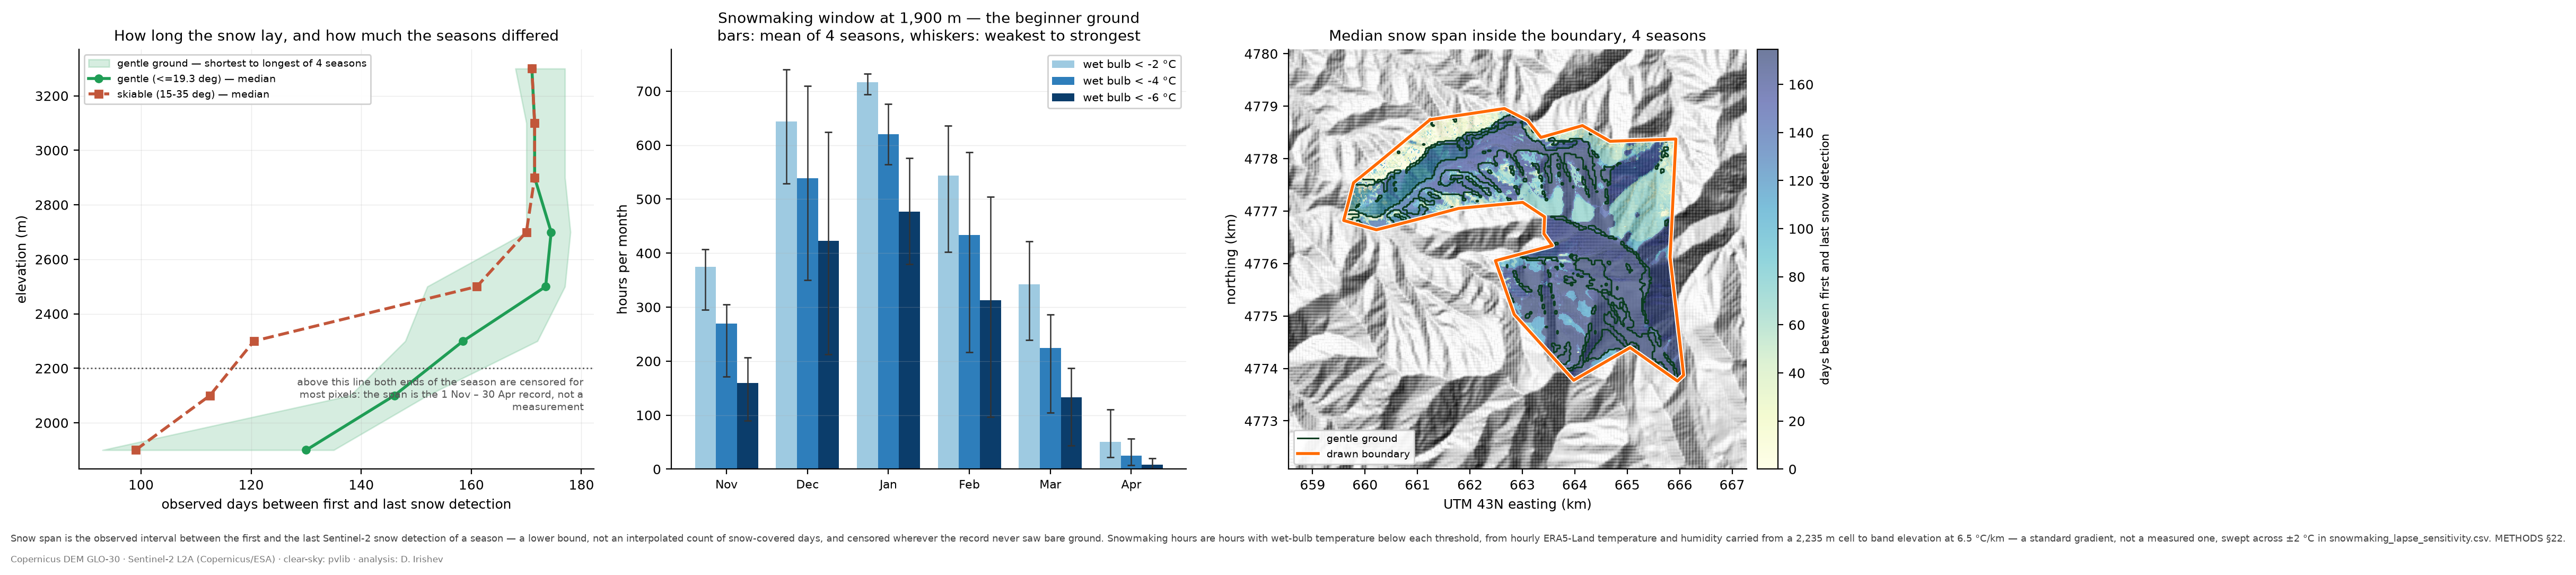

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/08_snow_sufficiency.png')

In [11]:
median_span = np.nanmedian(np.stack([SPANS[s]["span_days"] for s in SEASONS]), axis=0)
PS.figure(poly, DEM20, SLOPE20, M20, median_span, S2, SUMMARY, MAKING,
          gentle, 1900.0)

## 9. What this notebook cannot tell you

* **No depth, no water volume, no cost.** Production rate depends on water
  supply, pumping capacity and gun type, none of which is published. ERA5-Land
  does carry a modelled snow depth, and it is fetched and inspected, but no
  claim here rests on it: it is a 9 km cell's own snowpack at one elevation.
* **One reanalysis cell.** Every temperature descends from a single point,
  spread across 1,775–3,291 m by a fixed gradient. No local wind, no cold-air
  pooling, no valley inversion.
* **The satellite cannot see short thaws**, so continuity is an upper bound on
  how continuous the cover really was.
* **Four seasons is not a climatology**, nothing here is a forecast, and no
  probability is attached to any of it.
* **Sentinel-1 SAR** would see wet snow directly, through cloud and at night,
  and is the one addition that would turn "never seen to break" into a
  measurement. `DATA.md` §8 says why it is not here yet.

`METHODS.md` §22 is the full method; `DATA.md` §6.1 is where the hourly series
comes from and §11 lists the published work this chapter leans on.

## 10. Outputs

Everything on this page is written by one command:

```bash
KZ_AREA=superski python src/pipeline_snow_sufficiency.py
```

In [12]:
for pat in ("piste_snow_*.csv", "snowmaking_*.csv", "thaw_*.csv",
            "wet_bulb_*.csv"):
    for p in sorted(OUT_TAB.glob(pat)):
        print(f"   {p.name:42s} {p.stat().st_size / 1024:6.1f} KB")
print(f"\nfigure  -> {OUT_PNG / '08_snow_sufficiency.png'}")

   piste_snow_season_by_band.csv                 9.6 KB
   piste_snow_season_summary.csv                 2.9 KB
   piste_snow_sufficiency.csv                    2.9 KB
   snowmaking_hours_by_band_month.csv            4.6 KB
   snowmaking_lapse_sensitivity.csv              0.9 KB
   thaw_and_rain_on_snow_by_band.csv             6.3 KB
   thaw_lapse_sensitivity.csv                    1.4 KB
   wet_bulb_method_check.csv                     0.3 KB

figure  -> /Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/08_snow_sufficiency.png
